# ***Trabajo práctico N° 3 - Minería de datos (TUIA)***

## *Alumnos: Aldana Desiré Sánchez y Gastón Rinaldi*
### Año 2026
### Profesores:
### - Dr. Ing. Flavio E. Spetale (Resp. Cátedra)
### - Dr. Bioing. Ramiro Gatti
### - Tec. en IA Julieta López Ceratto

## Nota sobre las librerías utilizadas

En este trabajo usamos RAPIDS cuML (`cuml.svm.SVC` y `cuml.ensemble.RandomForestClassifier`) ejecutado en GPU, por su mayor eficiencia computacional: la exploración de hiperparámetros con validación cruzada (SVM con kernel RBF y Random Forest con 500 árboles) tarda segundos en lugar de minutos.

Ambas librerías (cuML y scikit-learn) son funcionales y tienen una API prácticamente idéntica, pero no son implementaciones idénticas (aleatoriedad propia de cada una, precisión de float32 en GPU vs. a `float64` en CPU, manejo de `max_depth=None`, etc.). Por eso, si se corre con scikit-learn, las métricas, los hiperparámetros óptimos y los tiempos pueden variar respecto a los que se ven en las conclusiones.

Para correrlo con scikit-learn alcanza con comentar las importaciones de cuML y descomentar las de scikit-learn.

In [3]:
# Librerías
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
import warnings
warnings.filterwarnings('ignore')

# --- Modelos: RAPIDS cuML (GPU) si está disponible; si no, scikit-learn (CPU) ---
try:
    import cuml
    from cuml.svm import SVC
    from cuml.ensemble import RandomForestClassifier
    print(f"RAPIDS cuML versión activa: {cuml.__version__}")
except ImportError:
    from sklearn.svm import SVC
    from sklearn.ensemble import RandomForestClassifier
    print("cuML no disponible: se usa scikit-learn en CPU (más lento).")


RAPIDS cuML versión activa: 26.06.00


'# --- Alternativa con scikit-learn (CPU) ---\nfrom sklearn.svm import SVC\nfrom sklearn.ensemble import RandomForestClassifier'

### Instalación de RAPIDS cuML (GPU)
Para entrenar los modelos de SVM y Random Forest en la GPU T4 se utiliza `cuml` de RAPIDS (en Colab ya viene instalado; la celda siguiente es solo una verificación).

In [4]:
# Solo para Google Colab con GPU (T4): instalación de RAPIDS cuML.
# En local o sin GPU se puede omitir: el notebook usa scikit-learn automáticamente.
# Instalación correcta de RAPIDS para Colab usando pip con soporte CUDA 12
#!pip install --extra-index-url=https://pypi.nvidia.com cuml-cu12==24.4.* cudf-cu12==24.4.* pylibraft-cu12==24.4.* rmm-cu12==24.4.*

# Verificación de que la instalación se realizó correctamente e importación de prueba
try:
    import cuml
    print(f"RAPIDS cuML instalado con éxito. Versión: {cuml.__version__}")
except ImportError:
    print("Error al importar cuML. Asegúrate de tener seleccionado el Entorno de Ejecución con GPU T4.")

Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com
  Using cached cuml_cu12-24.4.0.tar.gz (2.1 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> cuml-cu12

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
RAPIDS cuML instalado con éxito. Versión: 26.06.00


# Paso 1: EDA y limpieza de datos

In [5]:
# Lectura de dataset

df = pd.read_csv('crop_recommendation_geo.csv', sep=';')

df.head()

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,"1,353","6,689","13,5","7,233","11,167","24,867","31,017","16,867","24,868","15,185","31,804","65,161",1148,"126,689","19,228",96,arroz
1,"1,855","11,072","16,9","6,083","15,583","37,217","25,75","15,933","23,829","16,888","29,372","83,058",1740,"81,048","15,206",3,arroz
2,"1,727","14,273",29,"6,4","15,717","26,667",35,"23,683","18,029","7,566","27,969","77,17",1108,"65,502","11,994",316,arroz
3,"1,442","7,527",3,"6,283","18,067","36,7","27,3","19,083","18,042","6,62","28,075","78,908",1483,"51,357","13,621",343,arroz
4,"1,92","12,067","15,8","6,983","16,6","28,733","29,45","18,533","16,284","7,726","24,241","59,99",471,"83,554","16,836",6,arroz


In [6]:
# Estructura del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   N                       50004 non-null  object
 1   P                       50004 non-null  object
 2   exch_bases              50004 non-null  object
 3   ph                      50003 non-null  object
 4   soc                     50004 non-null  object
 5   arcilla                 50004 non-null  object
 6   arena                   50004 non-null  object
 7   cec                     50003 non-null  object
 8   temperatura             50004 non-null  object
 9   temp_min_mensual        50004 non-null  object
 10  temp_max_mensual        50004 non-null  object
 11  humedad                 50003 non-null  object
 12  lluvia                  50004 non-null  int64 
 13  estacionalidad_lluvias  50004 non-null  object
 14  radiacion_solar         50004 non-null  object
 15  el

In [7]:
# Observamos que todas las variables son numericas excepto por 'clase'
# pero no fueron detectadas automaticamente como floats porque en vez de utilizar '.'
# para marcar los decimales, usa ','. Procedemos a arreglarlo:

for col in df.columns.drop("clase"):
    df[col] = df[col].astype(str).str.replace(",", ".").astype(float)

# Chequeamos el cambio y continuamos con el EDA:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  float64
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null

In [8]:
df.describe()

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
count,50004.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50004.000000,50004.000000
mean,1.806235,10.306127,17.864335,6.478587,24.340227,31.240290,36.901901,20.456848,19.240280,11.908296,25.812635,66.837255,1155.215103,72.854064,16.769859,599.722062
std,0.962308,11.114586,11.976382,1.017599,26.461613,8.045335,13.559112,7.744750,7.717546,12.632699,5.250805,12.571507,832.849302,34.707992,2.274059,660.035470
min,0.265000,0.000000,0.100000,4.050000,1.017000,2.400000,0.883000,3.717000,-7.377000,-27.869000,0.585000,28.368000,3.000000,6.203000,6.274000,-161.000000
25%,1.098000,3.680000,7.000000,5.550000,11.017000,25.633000,28.017000,15.550000,14.217000,3.102750,22.238750,56.037000,483.000000,48.141250,15.115000,158.000000
50%,1.632000,6.668000,16.000000,6.500000,18.117000,31.033000,34.683000,19.550000,21.961500,16.445000,26.003500,69.340000,950.000000,68.367500,16.824000,385.000000
75%,2.272000,12.885250,26.500000,7.350000,27.183000,36.767000,45.033000,24.233000,25.789000,22.096750,28.978000,76.962000,1571.000000,94.025000,18.613000,811.000000
max,15.098000,180.000000,143.000000,25.317000,322.817000,142.383000,94.500000,70.817000,44.626000,27.918000,53.006000,148.141000,6759.000000,179.912000,22.882000,5476.000000


## Gráficos descriptivos

In [9]:
# Funcion auxiliar para graficar en grilla

def grilla(n, ncols=2, w=5, h=2.5):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes

## - Variables numéricas:

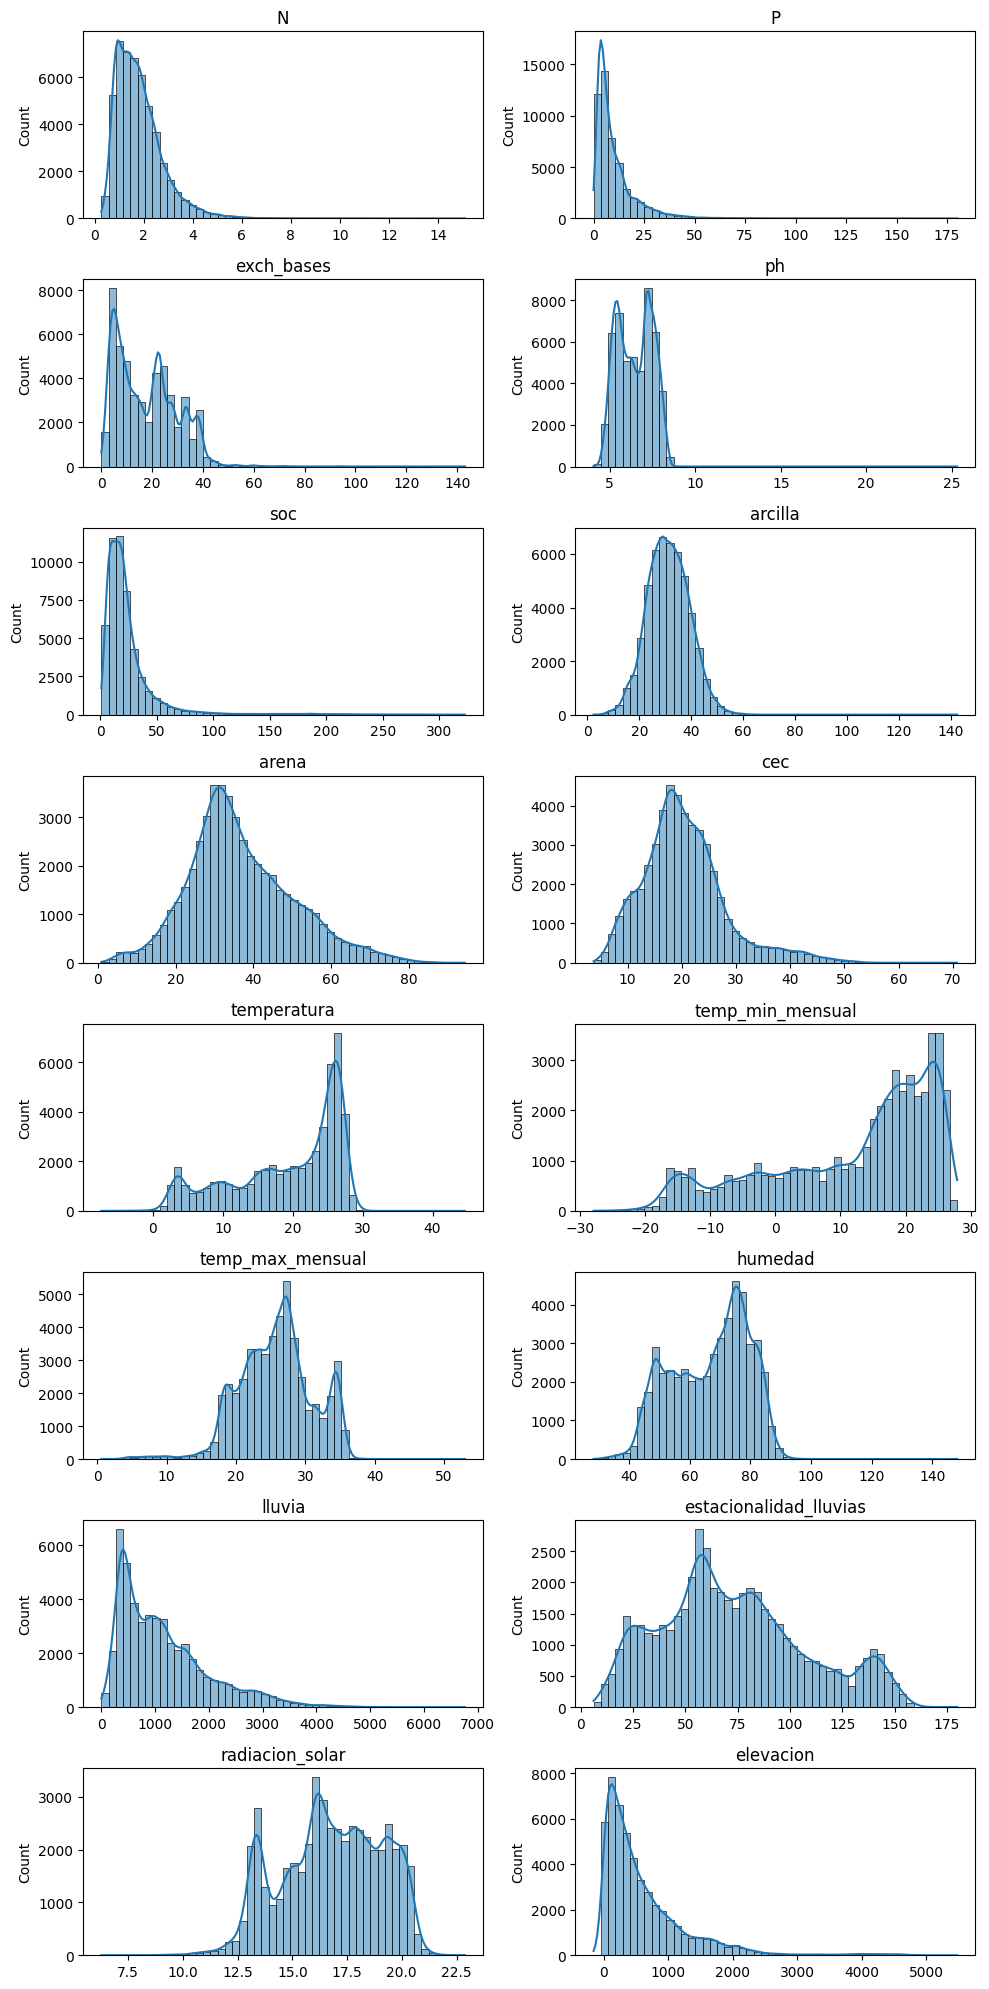

In [10]:
# Histograma + KDE (distribuciones)

fig, axes = grilla(len(df.columns) - 1)
for ax, col in zip(axes, df.columns[:-1]):
    sns.histplot(df[col], kde=True, bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Observaciones:
- Sesgo a la derecha: N, P, soc, lluvia y elevacion concentran la mayoría de los valores en los rangos bajos y tienen una cola larga hacia valores altos.
- Casi normales: arcilla tiene forma de campana, aunque con valores extremos aislados. arena y cec se parecen a una campana, pero con una cola derecha marcada, que corresponde a asimetría real y no solo a outliers.
- Multimodales (varios picos): exch_bases, ph, temp_max_mensual, humedad, radiacion_solar y estacionalidad_lluvias muestran dos o más picos.
- Sesgo a la izquierda y varios picos: temperatura y temp_min_mensual acumulan la mayoría de los valores en el rango alto, con una cola hacia temperaturas bajas.
- Valores fuera de rango: hay valores imposibles o sospechosos, como ph hasta 25 (el máximo posible es 14), arcilla de mas de 140 (debería llegar a 30). P, soc y exch_bases también tienen valores extremos que revisaremos mas adelante.

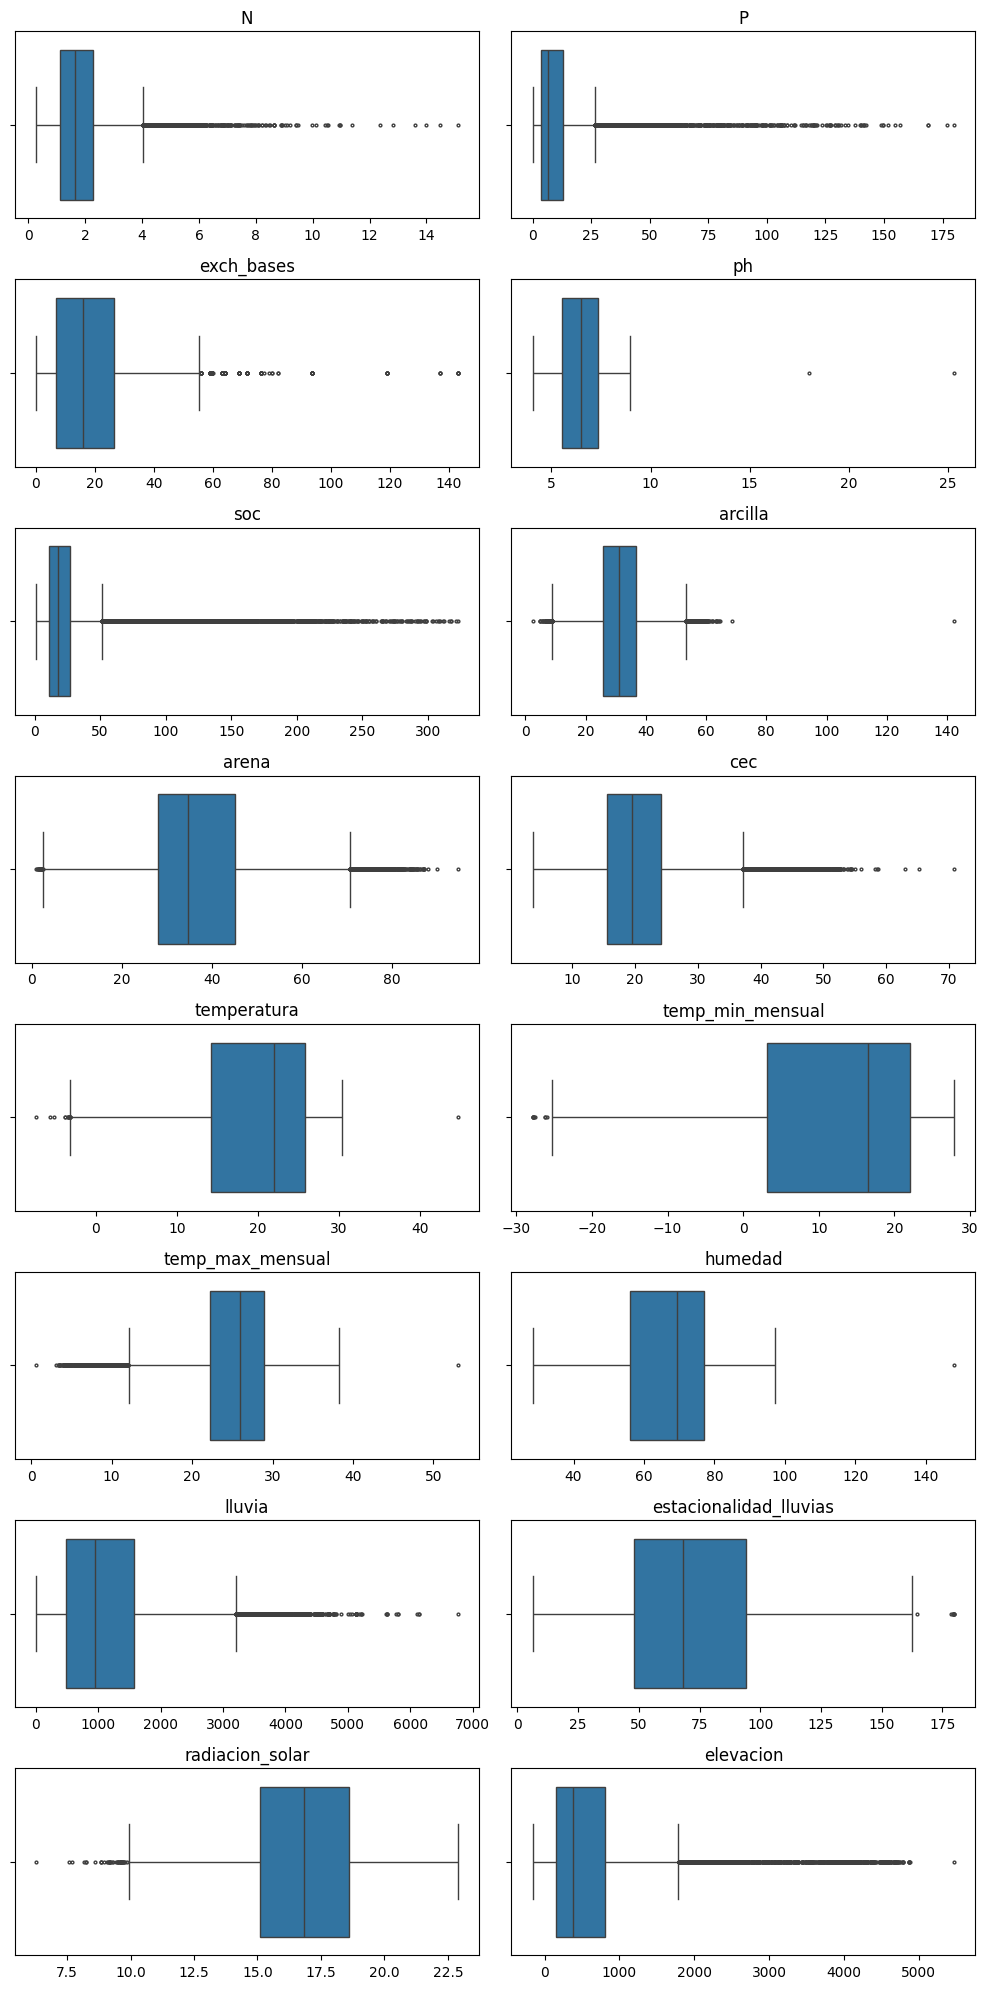

In [11]:
# Boxplots (outliers)

fig, axes = grilla(len(df.columns) - 1)
for ax, col in zip(axes, df.columns[:-1]):
    sns.boxplot(x=df[col], ax=ax, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Los boxplots confirman lo que mostraban los histogramas:

- Variables con sesgo a la derecha (N, P, soc, lluvia, elevacion): la mediana está pegada al límite inferior de la caja y hay una gran cantidad de puntos atípicos hacia valores altos. Estos puntos forman una cola continua y no son casos aislados, así que no necesariamente son errores.
- arena y cec: también muestran muchos atípicos hacia valores altos. Eso respalda que su asimetría es real y no se debe a unos pocos valores extremos.
- Variables simétricas o multimodales (temperatura, temp_min_mensual, humedad, estacionalidad_lluvias, radiacion_solar): tienen pocos atípicos y cajas amplias. Sin embargo, el boxplot no muestra los varios picos que se veían en los histogramas, porque oculta la multimodalidad.
- Valores extremos aislados: se ven puntos muy lejos del resto en ph (18 y 25), arcilla (142), humedad (148), temp_max_mensual (53) y temperatura (45), además de unos pocos en exch_bases. Son los candidatos más claros a errores de medición o carga, porque el pH no puede superar 14 y arcilla y humedad no pueden superar 100 %.

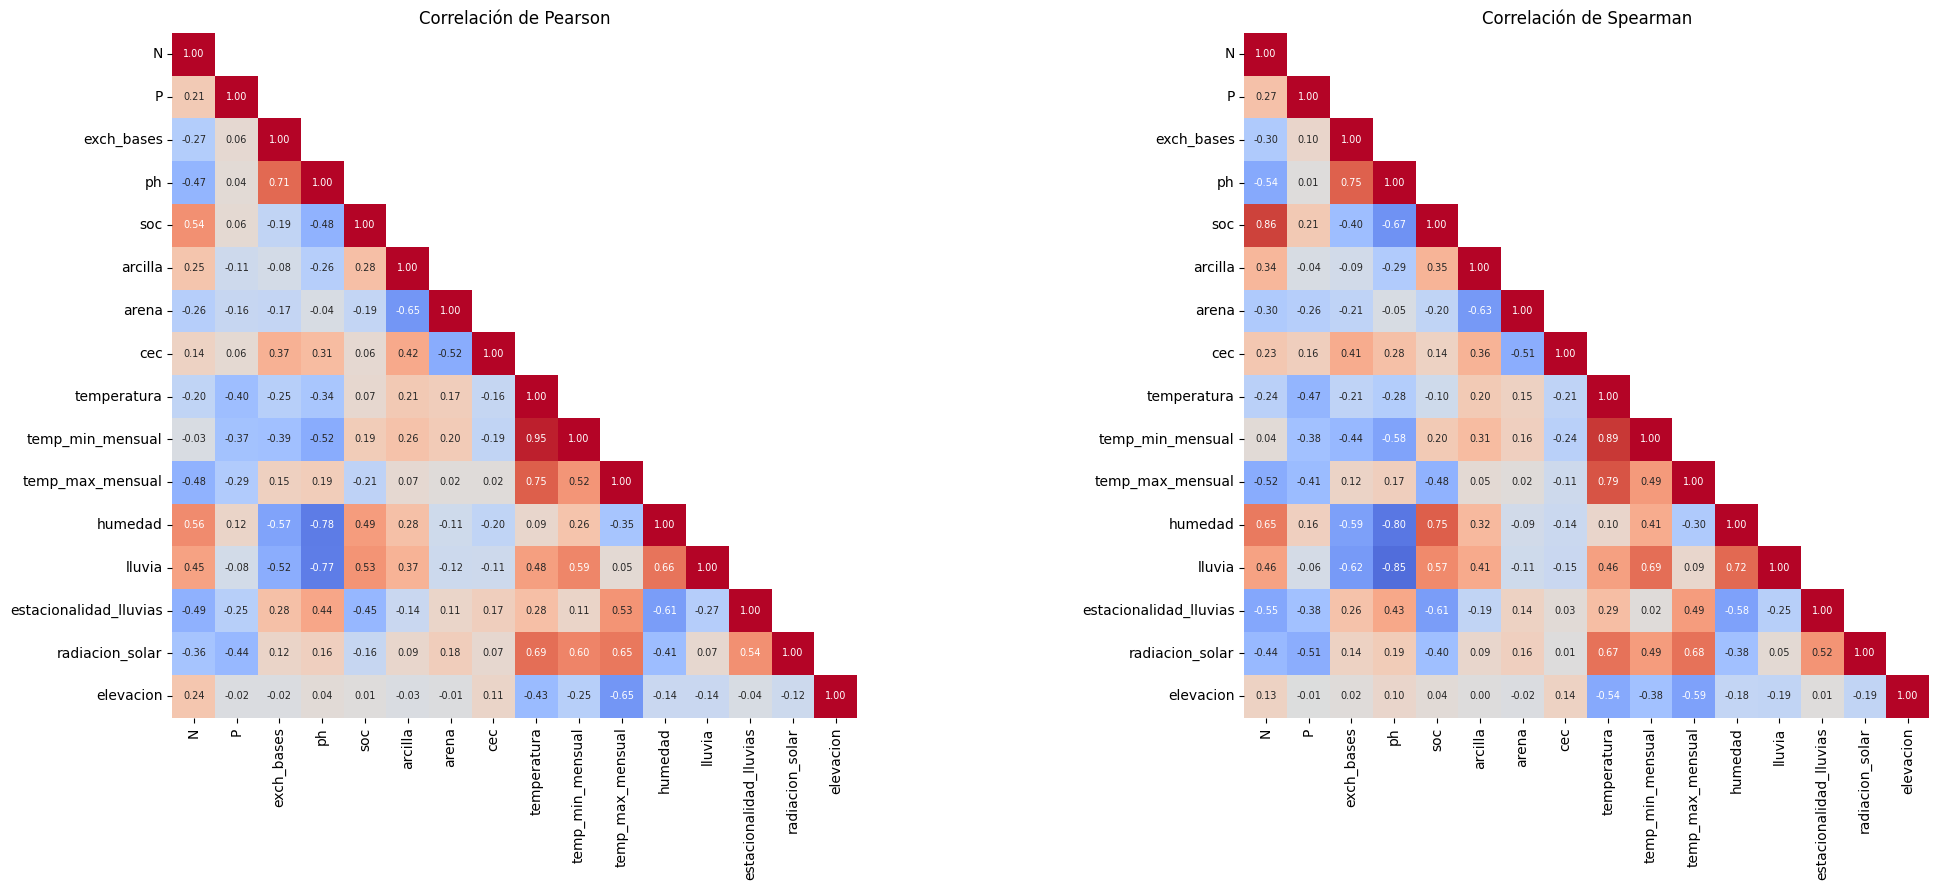

In [12]:
# Correlaciones de Pearson y Spearman

# Se excluye 'clase' porque es categórica; la correlación requiere variables numéricas.
datos_numericos = df.select_dtypes(include="number")
corr_p = datos_numericos.corr(method="pearson")
corr_s = datos_numericos.corr(method="spearman")

# Máscara: oculta el triángulo superior (información duplicada) y deja la diagonal
mascara = np.triu(np.ones(corr_p.shape, dtype=bool), k=1)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, corr, nombre in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, cbar=False,
                annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"Correlación de {nombre}")
plt.tight_layout()
plt.show()

Observamos una MUY fuerte correlacion de Pearson entre temp_min_mensual y temperatura, seguida por otras correlaciones fuertes como soc y N, lluvia y ph.

A pesar de estas fuertes correlaciones, en este trabajo no evaluaremos la multicolinealidad de dichas variables y conservaremos todas las predictoras del dataset.

### - Variable categórica: 'clase'

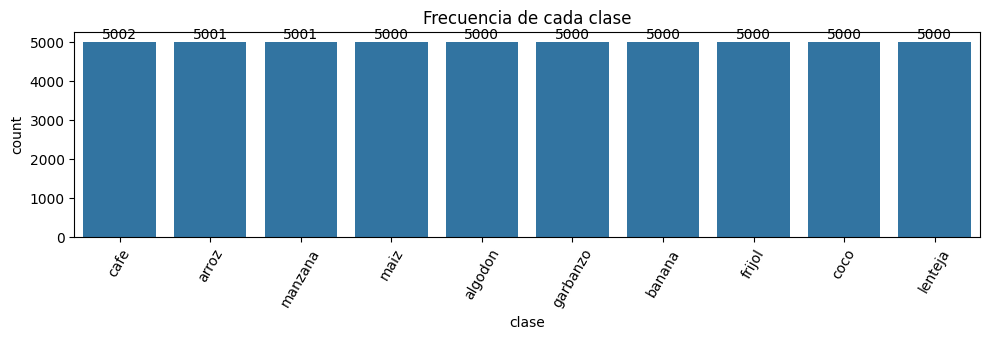

In [13]:
# Frecuencia de cada clase (balance)

orden = df["clase"].value_counts().index
plt.figure(figsize=(10, 3.5))
ax = sns.countplot(data=df, x="clase", order=orden)
ax.bar_label(ax.containers[0])
plt.xticks(rotation=60)
plt.title("Frecuencia de cada clase")
plt.tight_layout()
plt.show()

Observamos que las entradas de cada clase son practicamente parejas, lo que sugiere una previa limpieza del dataset o bien un dataset artificial.

## Valores faltantes

In [14]:
# Detectar valores faltantes por columna
nulos = df.isna().sum()
print("Valores faltantes por columna:")
print(nulos[nulos > 0])
print("\nFilas con al menos un valor faltante:", df.isna().any(axis=1).sum(), "de", len(df))
df[df.isna().any(axis=1)]

Valores faltantes por columna:
ph         1
cec        1
humedad    1
dtype: int64

Filas con al menos un valor faltante: 1 de 50004


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294.0,63.371,14.632,769.0,cafe


Hay valores faltantes en tres columnas (`ph`, `cec` y `humedad`), un único valor en cada una, y los tres pertenecen a una sola fila.

Estrategia: eliminar la fila. Representa menos del 0,01 % del dataset, por lo que su eliminación no altera la distribución de las clases ni de las variables. Imputar (media/mediana) implicaría inventar tres valores de una misma observación (suelo y clima a la vez) para recuperar un solo registro, sin ningún beneficio apreciable.

In [15]:
# Eliminamos las filas con valores nulos
n_antes = len(df)
df = df.dropna().reset_index(drop=True)
print("Filas eliminadas:", n_antes - len(df), "| Forma:", df.shape)

Filas eliminadas: 1 | Forma: (50003, 17)


## Registros duplicados

In [16]:
# Detectar filas duplicadas (filas idénticas en las 17 columnas)
n_dup = df.duplicated().sum()
print("Filas duplicadas (excluyendo la primera aparición):", n_dup)

# Distribución por clase de las filas repetidas
print("Duplicados por clase (incluye la primera aparición de cada grupo):")
print(df[df.duplicated(keep=False)]["clase"].value_counts())

Filas duplicadas (excluyendo la primera aparición): 198
Duplicados por clase (incluye la primera aparición de cada grupo):
clase
lenteja     218
manzana     110
algodon      28
garbanzo     24
maiz          6
frijol        6
arroz         4
Name: count, dtype: int64


Hay 198 registros duplicados (filas idénticas en todas las columnas, incluida la clase). No están repartidos al azar: se concentran en `lenteja` y `manzana`, lo que sugiere que fueron insertados al modificar el dataset.

Estrategia: eliminarlos conservando la primera aparición. Con 16 variables continuas es prácticamente imposible que dos mediciones reales coincidan en todas las columnas, así que son copias y no información nueva. Mantenerlos sesgaría las clases afectadas y, al hacer la partición train/validación/prueba, una misma fila podría caer en ambos conjuntos, inflando las métricas por fuga de datos (data leakage).

In [17]:
# Eliminar duplicados (conserva la primera aparición de cada uno)
df = df.drop_duplicates().reset_index(drop=True)

# Chequeo
print("Duplicadas restantes:", df.duplicated().sum(), "| Forma:", df.shape)

Duplicadas restantes: 0 | Forma: (49805, 17)


## Tratamiento de outliers

- N: en el histograma vemos que la distribución mantiene una forma conjunta hasta aproximadamente el valor 6 y luego se gener una cola.
En el boxplot, observamos que a partir del 4 todas las observaciones siguientes se consideran como outliers.
Pero desde nuestra perspectiva, el hecho de que haya una continuidad tan marcada entre dichos outliers demuestra que no son solo valores atípicos o mal cargados sino que pueden ser casos 'extremos' aun que reales.
Aun que, después del valor 12 aproximadamente, ya se corta esta 'continuidad' de la que hablamos y además dejan de ser una serie de filas atípicas y pasan a ser cargas aisladas. Por lo que decidimos que a partir de allí los consideraremos como outliers.

- P: observamos lo mismo que con N, siendo el punto de quiebre entre extremos y atípicos aprox. el 165.

- exch_bases: consideramos outliers a los valores mayores a 90.

- ph: mayores a 9.5 ya que en la realidad un cultivo no crece en suelos con ph mayores a 9.5.

- soc: aquí la colilla formada en ambos gráficos nos muestra que los vlores extremos mantienen una relación entre sí y que hay ucha densidad de estos. Por ende no haremos ninguna modificación.

- arcilla: por definicion debe ser menor o igual a 100.

- arena: colocamos el limite en 94,5 ya que esto representa un suelo extremadamente arenoso.

- cec: igual, a partir de 60.

- temperatura: quitamos el máximo, mayor a 40.

- temp_min_mensual: dejamos los da6tos tal cual están.

- temp_max_mensual: quitamos el mínimo y le máximo.

- humedad: como es un porcentaje, no puede pasar el 100.

- lluvia: consideramos putliers a aquellos valores que salen por duera d ela colilla generada por el gráfico: mayores a 5500.

- estacionalidad_lluvias: eliminamos los valores mayores a 175.

- radiación_solar: quitamos únicamente el mínimo.

- elevación: consideramos outlier solo al máximo.


Decidimos eliminar todas estas apariciones ya que en total, toda esta limpieza (sumada a la de filas duplicadas) representa mucho menos del 5% del total de entradas del dataset.

In [18]:
# Tratamiento de outliers según las condiciones definidas

# - N: consideraremos outliers a partir de 12 (filtramos valores menores o iguales a 12)
df = df[df['N'] <= 12]

# - P: punto de quiebre en aprox. 165 (filtramos menores o iguales a 165)
df = df[df['P'] <= 165]

# - exch_bases: consideramos outliers a los mayores a 90
df = df[df['exch_bases'] <= 90]

# - ph: mayores a 9.5
df = df[df['ph'] <= 9.5]

# - soc: no se hace ninguna modificación

# - arcilla: < o = a 100
df = df[df['arcilla'] <= 100]

# - arena: < o = a 94.5
df = df[df['arena'] <= 94.5]

# - cec: a partir de 60
df = df[df['cec'] <= 60]

# - temperatura: quitamos el máximo, mayor a 40 (menores o iguales a 40)
df = df[df['temperatura'] <= 40]

# - temp_min_mensual: dejamos los datos tal cual están

# - temp_max_mensual: quitamos el mínimo y el máximo (filtramos valores menores que el máximo y mayores que el mínimo del dataset original)
max_temp_max = df['temp_max_mensual'].max()
min_temp_max = df['temp_max_mensual'].min()
df = df[(df['temp_max_mensual'] > min_temp_max) & (df['temp_max_mensual'] < max_temp_max)]

# - humedad: < o = a 100
df = df[df['humedad'] <= 100]

# - lluvia: mayores a 5500
df = df[df['lluvia'] <= 5500]

# - estacionalidad_lluvias: eliminamos los valores mayores a 175
df = df[df['estacionalidad_lluvias'] <= 175]

# - radiacion_solar (escrito como 'radiacion_solar' en las columnas del df): quitamos únicamente el mínimo
min_radiacion = df['radiacion_solar'].min()
df = df[df['radiacion_solar'] > min_radiacion]

# - elevacion (escrito como 'elevacion' en las columnas del df): consideramos outlier solo al máximo
max_elevacion = df['elevacion'].max()
df = df[df['elevacion'] < max_elevacion]

# Reiniciamos los índices después de filtrar las filas
df = df.reset_index(drop=True)

print("Forma del DataFrame después de eliminar outliers:", df.shape)

Forma del DataFrame después de eliminar outliers: (49743, 17)


# Split train/test y split test en validacion/prueba

In [19]:
# Separación de variables predictoras y objetivo
X = df.drop(columns="clase")
y = df["clase"]

# 70% entrenamiento y 30% temporal; se divide este último en validación y prueba.
# Usamos stratify=y ya que en la limpieza se desbalancearon las clases.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=13)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=13)

# --- Escalado de X (se ajusta SOLO con train) ---
scaler = StandardScaler()
X_train_esc = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_val_esc   = pd.DataFrame(scaler.transform(X_val),   columns=X.columns, index=X_val.index)
X_test_esc  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

# --- Codificación de y (se ajusta SOLO con train) ---
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)

In [20]:
# Preparación común para los pasos 2, 3, 4 y 5

# cuML trabaja de forma óptima con float32 (X) e int32 (y)
X_train_esc_gpu = X_train_esc.astype('float32')
X_test_esc_gpu  = X_test_esc.astype('float32')
y_train_enc_gpu = y_train_enc.astype('int32')
y_test_enc_gpu  = y_test_enc.astype('int32')
# sklearn: no hace falta convertir; se pueden usar directamente X_train_esc / y_train_enc.

# Mismo esquema de validación cruzada en todos los pasos
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=13)

def evaluar_cv(crear_modelo, X, y, cv=cv):
    """Validación cruzada estratificada de un modelo.

    `crear_modelo` es una función sin argumentos que devuelve un modelo nuevo (sin entrenar).
    Devuelve media y desvío (5 folds) de accuracy, precision y recall (weighted),
    el accuracy medio en train (para detectar sobreajuste) y el tiempo medio de entrenamiento por fold.
    """
    acc, prec, rec, acc_tr, t_fit = [], [], [], [], []
    for idx_tr, idx_va in cv.split(X, y):
        modelo = crear_modelo()
        t0 = time.perf_counter()
        modelo.fit(X.iloc[idx_tr], y[idx_tr])
        t_fit.append(time.perf_counter() - t0)

        pred = np.asarray(modelo.predict(X.iloc[idx_va]))
        acc.append(accuracy_score(y[idx_va], pred))
        prec.append(precision_score(y[idx_va], pred, average='weighted'))
        rec.append(recall_score(y[idx_va], pred, average='weighted'))
        acc_tr.append(accuracy_score(y[idx_tr], np.asarray(modelo.predict(X.iloc[idx_tr]))))
    return {"acc_media": np.mean(acc),   "acc_std": np.std(acc),
            "prec_media": np.mean(prec), "prec_std": np.std(prec),
            "rec_media": np.mean(rec),   "rec_std": np.std(rec),
            "acc_train": np.mean(acc_tr), "t_fit": np.mean(t_fit)}

def mostrar_top(res, n=3):
    """Muestra las n mejores configuraciones por accuracy (para justificar la elección)."""
    cols = [c for c in res.columns if c not in ("acc_media", "acc_std", "prec_media", "prec_std",
                                                "rec_media", "rec_std", "acc_train", "t_fit")]
    print(res.nlargest(n, "acc_media")[cols + ["acc_media", "acc_std", "acc_train", "t_fit"]].round(4).to_string(index=False))

# Paso 2: SVC lineal

C=0.01  : Precision= 0.5978 ± 0.0040, Recall= 0.5979 ± 0.0028, Accuracy= 0.5979 ± 0.0028  (acc. train: 0.6011)
C=0.1   : Precision= 0.6146 ± 0.0018, Recall= 0.6164 ± 0.0014, Accuracy= 0.6164 ± 0.0014  (acc. train: 0.6191)
C=1.0   : Precision= 0.6213 ± 0.0023, Recall= 0.6223 ± 0.0018, Accuracy= 0.6223 ± 0.0018  (acc. train: 0.6246)
C=10.0  : Precision= 0.5154 ± 0.0194, Recall= 0.5323 ± 0.0185, Accuracy= 0.5323 ± 0.0185  (acc. train: 0.5371)
C=100.0 : Precision= 0.3678 ± 0.0236, Recall= 0.3652 ± 0.0269, Accuracy= 0.3652 ± 0.0269  (acc. train: 0.3676)

Mejor configuración SVM lineal: {'C': 1.0}


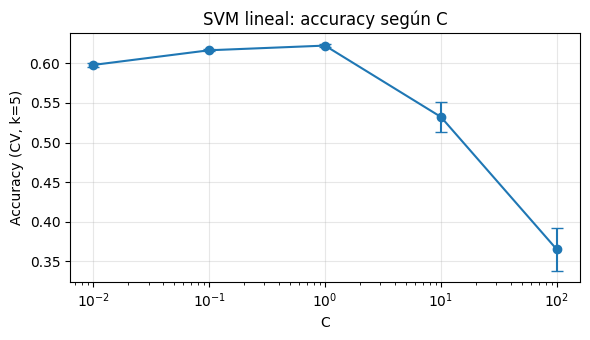

In [22]:
# SVC lineal: exploración del parámetro C (cuML, GPU)
# NOTA DE OPTIMIZACIÓN: Se agrega 'max_iter=50000' para evitar que el solver de la GPU
# entre en un bucle prolongado intentando converger con valores altos de C (como C=100),
# dado que los datos no son perfectamente separables de forma lineal.
Cs = [0.01, 0.1, 1, 10, 100]

filas = []
for C in Cs:
    r = evaluar_cv(lambda: SVC(kernel='linear', C=C, max_iter=50000, random_state=13),
                   X_train_esc_gpu, y_train_enc_gpu)
    filas.append({"C": C, **r})
res_lineal = pd.DataFrame(filas)

# Reporte: media ± desvío de 5 folds
for _, f in res_lineal.iterrows():
    print(f"C={f.C:<6}: Precision= {f.prec_media:.4f} ± {f.prec_std:.4f}, "
          f"Recall= {f.rec_media:.4f} ± {f.rec_std:.4f}, "
          f"Accuracy= {f.acc_media:.4f} ± {f.acc_std:.4f}  (acc. train: {f.acc_train:.4f})")

# Selección de la mejor configuración (mayor accuracy medio en CV)
fila_lineal = res_lineal.loc[res_lineal["acc_media"].idxmax()]
mejor_lineal = {"C": float(fila_lineal["C"])}
print("\nMejor configuración SVM lineal:", mejor_lineal)

# Gráfico: accuracy vs C (barras = desvío entre folds)
plt.figure(figsize=(6, 3.5))
plt.errorbar(res_lineal["C"], res_lineal["acc_media"], yerr=res_lineal["acc_std"], marker="o", capsize=4)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy (CV, k=5)")
plt.title("SVM lineal: accuracy según C")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Gráfico: el accuracy sube de ≈0.60 con C=0.01 a ≈0.62 con C=1 y luego cae abruptamente (≈0.53 con C=10, ≈0.37 con C=100).

Selección y justificación: elegimos C=1, que tiene el mayor accuracy medio en CV (0.622 ± 0.002). La ventaja sobre C=0.1 (0.616) es pequeña (~0.6 pts), aunque mayor que el desvío entre folds; en la práctica ambos son casi equivalentes y C=0.1 sería algo más simple. Mantenemos el criterio objetivo (máximo accuracy en CV) para que la elección sea reproducible.

Diagnóstico: el accuracy en train (≈0.625) es prácticamente igual al de CV (≈0.622), lo que indica subajuste: el modelo no está sobreajustando, sino que no captura la estructura de los datos. Afinar C solo mueve el accuracy unos pocos puntos, así que el límite parece estar en la capacidad del modelo y no en la regularización.

Suponemos entonces que las fronteras entre los 10 cultivos son no lineales, por l oque esperamos tener mejores resultados con kernel RBF y Random Forest.

# Paso 3: SVM  con  kernel  gaussiano  (RBF)

    C  gamma  acc_media  acc_std  prec_media  prec_std  rec_media  rec_std  acc_train  t_fit
  0.1  0.001     0.5129   0.0048      0.5065    0.0052     0.5129   0.0048     0.5131 1.4406
  0.1  0.010     0.5924   0.0027      0.5984    0.0030     0.5924   0.0027     0.5933 1.6627
  0.1  0.100     0.7258   0.0034      0.7276    0.0036     0.7258   0.0034     0.7327 1.2320
  0.1  1.000     0.7234   0.0054      0.8196    0.0042     0.7234   0.0054     0.7581 1.9710
  1.0  0.001     0.5763   0.0034      0.5794    0.0037     0.5763   0.0034     0.5771 1.1733
  1.0  0.010     0.6672   0.0011      0.6736    0.0016     0.6672   0.0011     0.6707 1.0964
  1.0  0.100     0.8116   0.0026      0.8108    0.0029     0.8116   0.0026     0.8295 1.2056
  1.0  1.000     0.8687   0.0046      0.8729    0.0043     0.8687   0.0046     0.9519 2.6190
 10.0  0.001     0.6279   0.0016      0.6295    0.0025     0.6279   0.0016     0.6298 1.1530
 10.0  0.010     0.7418   0.0024      0.7429    0.0027     0.7418   0.

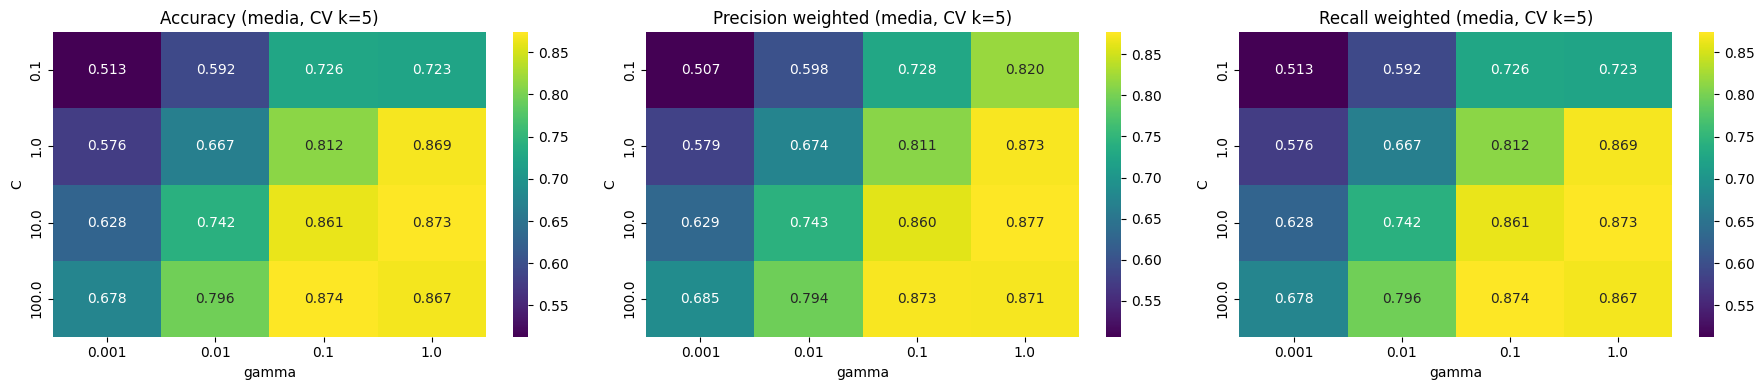

Mejor configuración SVM RBF: {'C': 100.0, 'gamma': 0.1}
Accuracy CV: 0.8736 ± 0.0029 | Accuracy en train: 0.9552

Tres mejores configuraciones:
    C  gamma  acc_media  acc_std  acc_train  t_fit
100.0    0.1     0.8736   0.0029     0.9552 3.3614
 10.0    1.0     0.8726   0.0053     0.9917 2.5480
  1.0    1.0     0.8687   0.0046     0.9519 2.6190


In [24]:
# SVC con kernel RBF: exploración de C y gamma (cuML, GPU)
C_vals = [0.1, 1, 10, 100]
gamma_vals = [0.001, 0.01, 0.1, 1]

filas = []
for C in C_vals:
    for g in gamma_vals:
        r = evaluar_cv(lambda: SVC(kernel="rbf", C=C, gamma=g, random_state=13),
                       X_train_esc_gpu, y_train_enc_gpu)
        # sklearn: es el mismo código (SVC de sklearn con kernel='rbf'); en CPU esta grilla es mucho más lenta
        filas.append({"C": C, "gamma": g, **r})
res_rbf = pd.DataFrame(filas)
print(res_rbf.round(4).to_string(index=False))

### Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (m, titulo) in zip(axes, [("acc_media", "Accuracy"),
                                  ("prec_media", "Precision weighted"),
                                  ("rec_media", "Recall weighted")]):
    tabla = res_rbf.pivot(index="C", columns="gamma", values=m)
    sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(f"{titulo} (media, CV k=5)")
plt.tight_layout()
plt.show()

# Selección de la mejor configuración (mayor accuracy medio en CV)
fila_rbf = res_rbf.loc[res_rbf["acc_media"].idxmax()]
mejor_rbf = {"C": float(fila_rbf["C"]), "gamma": float(fila_rbf["gamma"])}
print("Mejor configuración SVM RBF:", mejor_rbf)
print(f"Accuracy CV: {fila_rbf.acc_media:.4f} ± {fila_rbf.acc_std:.4f} | Accuracy en train: {fila_rbf.acc_train:.4f}")
print("\nTres mejores configuraciones:")
mostrar_top(res_rbf)

Los tres heatmaps son casi idénticos y muestran el mismo patrón:

- Con gamma pequeño (0.001) el modelo rinde mal en todos los C: el kernel es tan ancho que la frontera es casi lineal y se produce subajuste, igual que en el SVM lineal.
- El rendimiento mejora al aumentar C y gamma a la vez: la zona buena es la esquina inferior derecha. Se compensan entre sí: un C chico necesita un gamma grande y viceversa.
- El máximo está en C=100, gamma=0.1 (accuracy ≈0.874). Pasar a gamma=1 ya no mejora: con C=100 el accuracy baja (≈0.867) y con C=10 queda prácticamente igual (≈0.873, dentro del desvío entre folds). Con gamma=1 el accuracy en train llega a ≈0.99–1.00 para C=10 y C=100, señal de que el kernel ya es demasiado angosto y el modelo empieza a memorizar.
- Con C=0.1 y gamma=1 el precision (≈0.82) queda muy por encima del recall (≈0.72): el modelo está tan regularizado que predice bien solo algunas clases e ignora otras.

Esto coincide con lo esperado: un modelo no lineal debía superar claramente al lineal (≈0.62), y lo hace en ≈25 puntos de accuracy.

Selección y justificación: elegimos la combinación con mayor accuracy medio en CV, C=100, gamma=0.1**. Su desvío entre folds es muy bajo (≈0.003), por lo que el resultado es estable. Las tres mejores configuraciones (C=100/gamma=0.1, C=10/gamma=1 y C=1/gamma=1) difieren menos de 0.005 en accuracy, es decir, son prácticamente equivalentes; la elegida es además la que menos sobreajusta entre las tres (accuracy en train ≈0.96 contra ≈0.99 de C=10/gamma=1). Aun así, el accuracy en train (≈0.96) es bastante mayor que el de validación (≈0.87): existe cierto sobreajuste, aunque la validación cruzada (que es la que usamos para elegir) ya lo penaliza.

# Paso 4: Implementación del RandomForestClassifier


 n_estimators max_depth  acc_media  acc_std  prec_media  prec_std  rec_media  rec_std  acc_train  t_fit
           50         5     0.6391   0.0032      0.6580    0.0018     0.6391   0.0032     0.6459 0.1905
           50        10     0.8302   0.0044      0.8327    0.0046     0.8302   0.0044     0.8763 0.2663
           50        20     0.8988   0.0021      0.8981    0.0022     0.8988   0.0021     0.9960 0.3508
           50      None     0.9010   0.0022      0.9002    0.0023     0.9010   0.0022     0.9998 0.3793
          100         5     0.6404   0.0035      0.6588    0.0040     0.6404   0.0035     0.6461 0.4120
          100        10     0.8322   0.0046      0.8349    0.0051     0.8322   0.0046     0.8780 0.5214
          100        20     0.9013   0.0029      0.9008    0.0030     0.9013   0.0029     0.9967 0.7170
          100      None     0.9031   0.0034      0.9024    0.0034     0.9031   0.0034     0.9999 0.8423
          200         5     0.6408   0.0045      0.6594    0.005

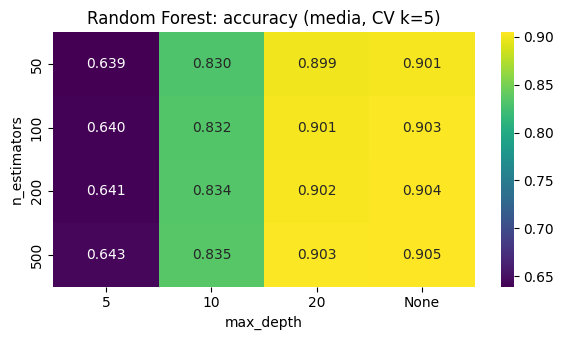

Mejor configuración Random Forest: {'n_estimators': 500, 'max_depth': None}
Accuracy CV: 0.9047 ± 0.0038 | Accuracy en train: 0.9999

Tres mejores configuraciones:
 n_estimators max_depth  acc_media  acc_std  acc_train  t_fit
          500      None     0.9047   0.0038     0.9999 4.1981
          200      None     0.9039   0.0032     0.9999 1.6469
          100      None     0.9031   0.0034     0.9999 0.8423


In [ ]:
# Random Forest: exploración de n_estimators y max_depth (cuML, GPU)
n_estimators = [50, 100, 200, 500]
max_depths = [5, 10, 20, None]
# Nota: los árboles no necesitan escalado; pero de todos modos usamos los mismos datos escalados por consistencia con los otros pasos.

configs_rf = [(n, d) for n in n_estimators for d in max_depths]
filas = []
for n, d in configs_rf:
    r = evaluar_cv(lambda: RandomForestClassifier(n_estimators=n, max_depth=d, random_state=13),
                   X_train_esc_gpu, y_train_enc_gpu)
    # sklearn: RandomForestClassifier(n_estimators=n, max_depth=d, random_state=13, n_jobs=-1)
    #          (en sklearn max_depth=None significa profundidad ilimitada)
    filas.append({"n_estimators": n, "max_depth": str(d), **r})
res_rf = pd.DataFrame(filas)
print(res_rf.round(4).to_string(index=False))

# Heatmap de accuracy
tabla = res_rf.pivot(index="n_estimators", columns="max_depth", values="acc_media")[["5", "10", "20", "None"]]
plt.figure(figsize=(6, 3.5))
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis")
plt.title("Random Forest: accuracy (media, CV k=5)")
plt.tight_layout()
plt.show()

# Selección de la mejor configuración (mayor accuracy medio en CV)
i_mejor = res_rf["acc_media"].idxmax()
fila_rf = res_rf.loc[i_mejor]
n_mejor, d_mejor = configs_rf[i_mejor]
mejor_rf = {"n_estimators": n_mejor, "max_depth": d_mejor}
print("Mejor configuración Random Forest:", mejor_rf)
print(f"Accuracy CV: {fila_rf.acc_media:.4f} ± {fila_rf.acc_std:.4f} | Accuracy en train: {fila_rf.acc_train:.4f}")
print("\nTres mejores configuraciones:")
mostrar_top(res_rf)

Según el heatmap, la profundidad es el hiperparámetro que más pesa: con max_depth=5 los árboles son demasiado simples (accuracy ≈0.64), con 10 sube a ≈0.83 y con 20 o sin límite se estabiliza en ≈0.90. En cambio, la cantidad de árboles tiene un efecto mucho menor: pasar de 50 a 100–500 árboles agrega solo entre 0.1 y 0.4 puntos de accuracy, del orden del desvío entre folds (≈0.003–0.004). Es el comportamiento esperado: más árboles reducen la varianza hasta que se llega a una meseta.

Selección y justificación: la configuración con mayor accuracy medio en CV es n_estimators=500 con max_depth=None (0.9047 ± 0.0038). Como las diferencias entre las mejores configuraciones (≥100 árboles y profundidad 20 o ilimitada: entre 0.901 y 0.905) son muy pequeñas y están dentro del desvío entre folds, cualquiera de ellas sería equivalente en la práctica; con 100 árboles el entrenamiento tarda más que con 500, para un accuracy casi igual. Mantenemos el criterio objetivo (máximo accuracy) para que la elección sea reproducible. Los desvíos son bajos (≈0.002–0.004), por lo que el modelo es estable entre folds. Con profundidad 20 o ilimitada el accuracy en train es ≈1.00 contra ≈0.90 en validación: los árboles memorizan el train, aunque la validación cruzada muestra que aun así generalizan bien.

Importancias calculadas con: cuML

Top 5 variables:
temp_min_mensual    0.1136
radiacion_solar     0.0957
lluvia              0.0912
temp_max_mensual    0.0912
humedad             0.0847

Importancia total - variables de suelo: 0.290 | variables de clima/relieve: 0.710


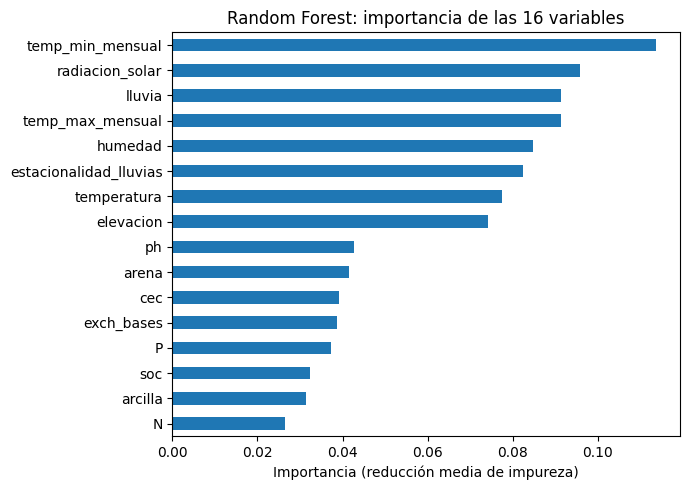

In [26]:
# Importancia de variables del mejor Random Forest
rf_final = RandomForestClassifier(**mejor_rf, random_state=13)
rf_final.fit(X_train_esc_gpu, y_train_enc_gpu)

try:
    importancias = np.asarray(rf_final.feature_importances_)
    fuente = "cuML"
except (AttributeError, NotImplementedError):
    # Algunas versiones de cuML no exponen feature_importances_: se reentrena el mismo modelo
    # (mismos hiperparámetros) con scikit-learn en CPU solo para obtener las importancias.
    from sklearn.ensemble import RandomForestClassifier as RandomForestSklearn
    rf_cpu = RandomForestSklearn(**mejor_rf, random_state=13, n_jobs=-1)
    rf_cpu.fit(X_train_esc, y_train_enc)
    importancias = rf_cpu.feature_importances_
    fuente = "scikit-learn (CPU)"
# sklearn: rf_final.feature_importances_ funciona directamente

imp = pd.Series(importancias, index=X_train_esc.columns).sort_values()
print(f"Importancias calculadas con: {fuente}")
print("\nTop 5 variables:")
print(imp.sort_values(ascending=False).head(5).round(4).to_string())

suelo = ["N", "P", "exch_bases", "ph", "soc", "arcilla", "arena", "cec"]
print(f"\nImportancia total - variables de suelo: {imp[suelo].sum():.3f} | variables de clima/relieve: {imp.drop(suelo).sum():.3f}")

plt.figure(figsize=(7, 5))
imp.plot(kind="barh")
plt.xlabel("Importancia (reducción media de impureza)")
plt.title("Random Forest: importancia de las 16 variables")
plt.tight_layout()
plt.show()

El gráfico ordena las 16 variables según cuánto influyen en promedio en la clasificación, y en total suman 1. Las cinco más importantes son todas climáticas. Además, la importancia está bastante repartida: ninguna variable supera 0.12, así que el modelo se apoya en muchas variables a la vez y no en una sola.

Hay que leer el ranking con cuidado: en el EDA vimos que temperatura y temp_min_mensual están muy correlacionadas, y cuando dos variables aportan información redundante el Random Forest reparte la importancia entre ellas, de modo que cada una parece menos relevante de lo que es en conjunto. Además, esta medida puede favorecer a las variables continuas con muchos valores distintos. Por eso el ranking indica qué variables usa el modelo, no una relación causal entre variable y cultivo.

# Paso 5: Comparación de modelos

,Accuracy (CV),Precision (CV),Recall (CV),Accuracy (test),Precision (test),Recall (test),Tiempo entrenamiento (s)
Modelo,,,,,,,
SVM lineal,0.6223 ± 0.0018,0.6213 ± 0.0023,0.6223 ± 0.0018,0.6147,0.6136,0.6147,5.3105
SVM RBF,0.8736 ± 0.0029,0.8727 ± 0.0031,0.8736 ± 0.0029,0.8819,0.8807,0.8819,4.2287
Random Forest,0.9047 ± 0.0038,0.9041 ± 0.0040,0.9047 ± 0.0038,0.9145,0.9141,0.9145,4.3531



Modelo con mayor accuracy en test: Random Forest


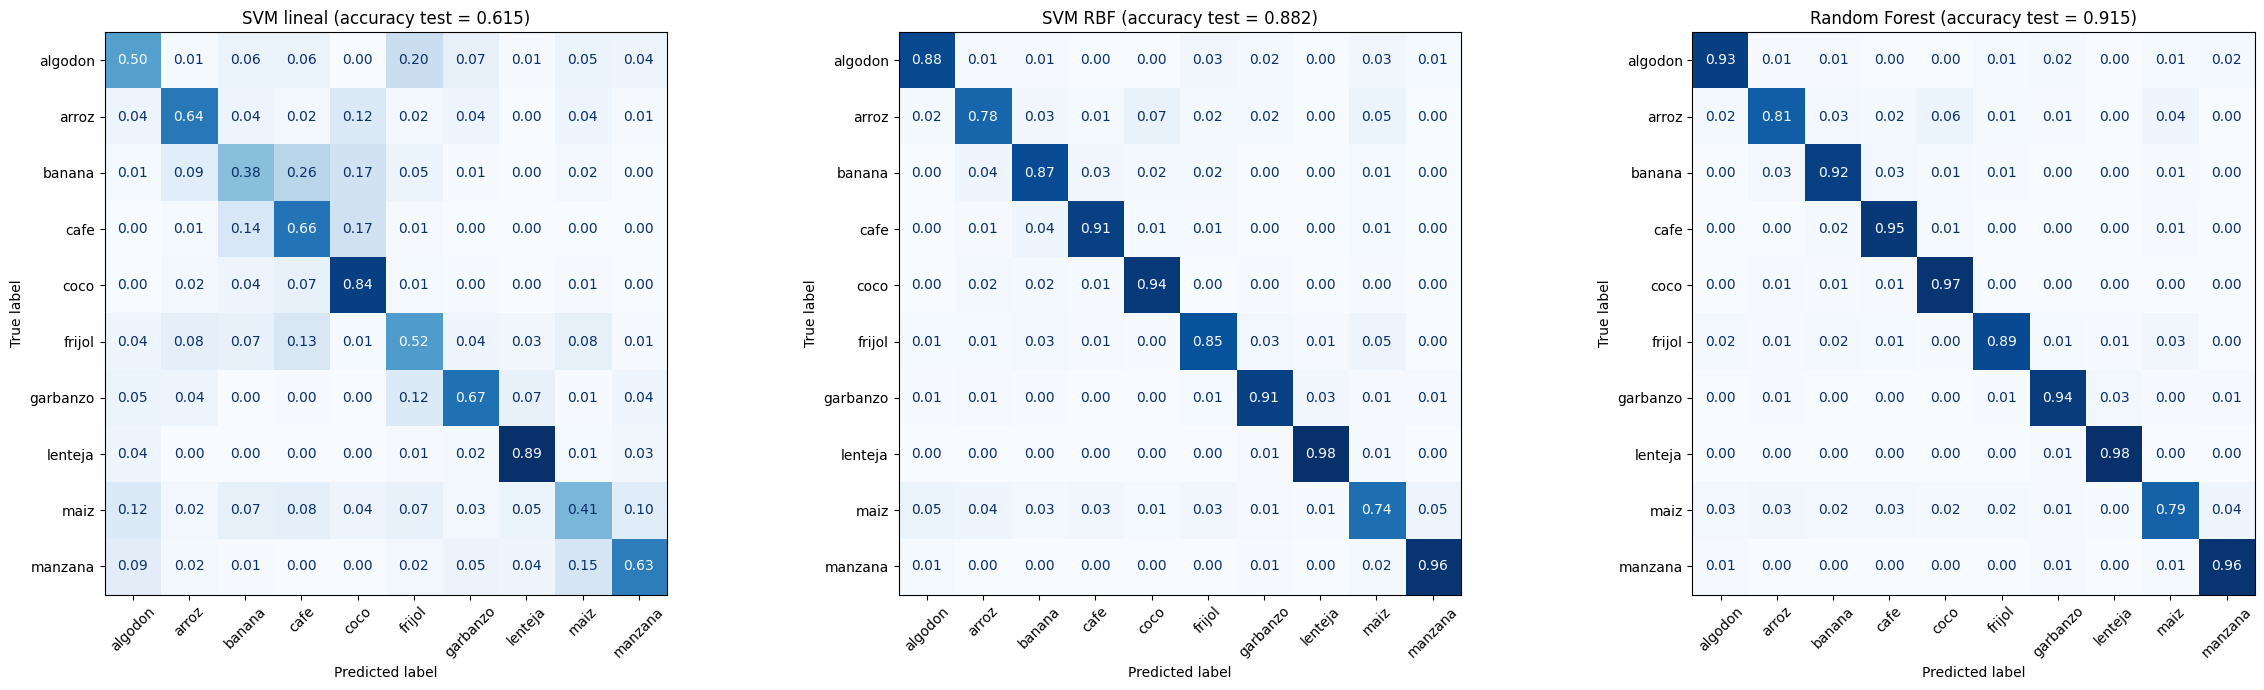

SVM lineal     -> menor recall: banana (0.38), maiz (0.41), algodon (0.50)
SVM RBF        -> menor recall: maiz (0.74), arroz (0.78), frijol (0.85)
Random Forest  -> menor recall: maiz (0.79), arroz (0.81), frijol (0.89)


In [ ]:
# Comparación de los mejores modelos de cada algoritmo
# (los hiperparámetros salen de los pasos 2, 3 y 4)

modelos = {
    "SVM lineal":    lambda: SVC(kernel="linear", C=mejor_lineal["C"], random_state=13),
    "SVM RBF":       lambda: SVC(kernel="rbf", C=mejor_rbf["C"], gamma=mejor_rbf["gamma"], random_state=13),
    "Random Forest": lambda: RandomForestClassifier(**mejor_rf, random_state=13),
    # sklearn: igual, agregando n_jobs=-1 en el Random Forest
}
filas_cv = {"SVM lineal": fila_lineal, "SVM RBF": fila_rbf, "Random Forest": fila_rf}

filas_tabla, preds = [], {}
for nombre, crear in modelos.items():
    modelo = crear()
    t0 = time.perf_counter()
    modelo.fit(X_train_esc_gpu, y_train_enc_gpu)           # entrenamiento sobre todo el train
    t_entren = time.perf_counter() - t0
    pred = np.asarray(modelo.predict(X_test_esc_gpu))
    preds[nombre] = pred

    f = filas_cv[nombre]
    filas_tabla.append({
        "Modelo": nombre,
        "Accuracy (CV)":  f"{f.acc_media:.4f} ± {f.acc_std:.4f}",
        "Precision (CV)": f"{f.prec_media:.4f} ± {f.prec_std:.4f}",
        "Recall (CV)":    f"{f.rec_media:.4f} ± {f.rec_std:.4f}",
        "Accuracy (test)": accuracy_score(y_test_enc_gpu, pred),
        "Precision (test)": precision_score(y_test_enc_gpu, pred, average="weighted"),
        "Recall (test)":    recall_score(y_test_enc_gpu, pred, average="weighted"),
        "Tiempo entrenamiento (s)": t_entren})

tabla_comp = pd.DataFrame(filas_tabla).set_index("Modelo")
display(tabla_comp.round(4))

mejor_test = tabla_comp["Accuracy (test)"].idxmax()
print(f"\nModelo con mayor accuracy en test: {mejor_test}")

# Matrices de confusión (conjunto de prueba, normalizadas por fila = recall de cada clase)
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (nombre, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_enc_gpu, pred, display_labels=le.classes_, normalize="true",
        cmap="Blues", values_format=".2f", xticks_rotation=45, colorbar=False, ax=ax)
    ax.set_title(f"{nombre} (accuracy test = {accuracy_score(y_test_enc_gpu, pred):.3f})")
plt.tight_layout()
plt.show()

# Clases más difíciles para cada modelo (recall por clase)
for nombre, pred in preds.items():
    cm = confusion_matrix(y_test_enc_gpu, pred)
    rec_clase = pd.Series(np.diag(cm) / cm.sum(axis=1), index=le.classes_).sort_values()
    print(f"{nombre:14} -> menor recall: " + ", ".join(f"{c} ({v:.2f})" for c, v in rec_clase.head(3).items()))

En la matriz de confusión, cada fila está normalizada, así que la diagonal es el recall de cada clase. En el SVM lineal la diagonal es débil y hay mucha confusión repartida entre varios cultivos, coherente con el accuracy de ≈0.61: el modelo no logra separar linealmente las clases y sus peores clases son banana, maiz y algodon. En el SVM RBF y sobre todo en el Random Forest la diagonal se vuelve mucho más marcada. En ambos modelos no lineales las clases más difíciles son las mismas, maiz, arroz y frijol; el resto de los cultivos queda por encima de esos valores.

Comparación y elección del modelo:

- Métricas: el orden es Random Forest > SVM RBF > SVM lineal, tanto en CV (0.905 > 0.874 > 0.622) como en test (0.915 > 0.882 > 0.615). El accuracy en test es muy parecido al de CV en los tres modelos (en los dos no lineales incluso algo mayor), por lo que los resultados se mantienen sobre datos no vistos. Accuracy, precision y recall son prácticamente iguales porque las clases están balanceadas.
- Estabilidad: los tres modelos tienen desvíos bajos entre folds (≈0.002–0.004), por lo que la diferencia entre algoritmos (≈3 puntos entre Random Forest y SVM RBF, ≈25 entre SVM RBF y SVM lineal) es mayor que la variabilidad de cada uno: es una diferencia real y no azar de la partición.
- Interpretabilidad: el SVM lineal es el más simple, pero su bajo rendimiento lo descarta. El SVM RBF es una caja negra (no entrega una medida directa del aporte de cada variable). El Random Forest tampoco es transparente árbol por árbol, pero entrega la importancia de cada variable, lo que permite explicar qué factores pesan más en la recomendación.
- Tiempo de entrenamiento: en esta corrida (GPU con cuML) los tres modelos tardan vcasi lo mismo, no hay una diferencia que incline la decisión. En CPU con scikit-learn el SVM con kernel RBF suele ser el más lento porque su costo crece con el número de muestras.

Modelo elegido: Random Forest. Obtiene el mayor accuracy (≈0.915 en test), es estable entre folds y es el más interpretable de los dos modelos competitivos gracias a feature_importances_. El SVM RBF queda como alternativa cercana. Ambos muestran sobreajuste en train (≈0.96 el SVM RBF y ≈1.00 el Random Forest, contra ≈0.87 y ≈0.90 en validación), pero como el accuracy en test coincide con el de CV, la capacidad de generalización no se ve afectada.

# Conclusiones

- Preparación de datos: el dataset (modificado intencionalmente) tenía una fila con valores faltantes, 198 filas duplicadas concentradas en lenteja y manzana y valores imposibles (por ejemplo, pH hasta 25 o arcilla de 140). Se eliminaron los faltantes y duplicados evitando fuga de datos entre train y test y se filtraron los outliers claramente erróneos, perdiendo menos del 1 % de los registros.
- SVM lineal: accuracy ≈0.62 en CV (≈0.61 en test) casi independiente de C. Las clases no son linealmente separables, por lo que el modelo subajusta.
- SVM RBF: accuracy ≈0.87 en CV (≈0.88 en test) con C=100 y gamma=0.1. El kernel no lineal aporta unos 25 puntos sobre el lineal, a costa de cierto sobreajuste (≈0.96 en train) y menor interpretabilidad.
- Random Forest: accuracy ≈0.90 en CV (≈0.91 en test), el mejor resultado, con baja variabilidad entre folds. La profundidad de los árboles es el hiperparámetro más influyente; la cantidad de árboles importa poco a partir de ≈100.
- Modelo 'ganador'': Random Forest, por rendimiento, estabilidad e interpretabilidad (importancia de variables).
- Limitaciones: los resultados dependen de la librería usada (cuML en GPU frente a scikit-learn en CPU), de la grilla explorada (pequeña) y de las decisiones de limpieza de outliers. Una búsqueda más fina de hiperparámetros o el tratamiento de la multicolinealidad entre variables podrían cambiar (incluso mejorar) los resultados.